# Машинное обучение
# Задание 1. Ridge-регрессия

Дата выдачи: 07.09.2026

### О задании

Вы научитесь:
 * подготавливать данные для обучения линейных моделей;
 * обучать Ridge-регрессию при помощи модуля scikit-learn;
 * вычислять ошибки на валидационной и тренировочной выборках;
 * проверять модель на переобучение;
 * оценивать качество модели

#### Шаг 1. Скачайте датасет, откройте его и выведите таблицу на экран

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 200)
data = pd.read_csv("apartment_dataset.csv")
display(data)

Matplotlib is building the font cache; this may take a moment.


,apartment id,rooms,total area,floor,complex rating,price
0,1,2,60.8,9,4.2,11.54
1,2,4,102.5,17,4.6,20.22
2,3,3,75.7,17,4.9,15.74
3,4,2,66.0,20,4.7,14.10
4,5,1,39.7,16,3.6,6.71
5,6,1,30.1,25,4.0,6.85
6,7,1,31.6,22,3.4,5.53
7,8,3,87.3,13,4.9,17.97
8,9,2,48.1,19,4.3,10.10
9,10,3,75.7,17,3.6,12.80


#### Шаг2. Разделите выборку на тренировочную валидационную и тестовую:
* в тренировочной: 100 первых квартир;
* в валидационной: 50 следующих квартир; 
* в тестовой: 50 последних квартир.
* в каждой выборке матрица X - это столбцы rooms, total area, floor, complex rating, а y - столбец price. 

Названия: X_train, y_train, X_val, y_val, X_test, y_test. 

In [2]:
features = ["rooms", "total area", "floor", "complex rating"]

X_train = data.iloc[:100][features]
y_train = data.iloc[:100]["price"]
X_val = data.iloc[100:150][features]
y_val = data.iloc[100:150]["price"]
X_test = data.iloc[150:][features]
y_test = data.iloc[150:]["price"]

print("Размеры выборок:", len(X_train), len(X_val), len(X_test))
print("Пропуски:", data.isna().sum().sum())

Размеры выборок: 100 50 50
Пропуски: 0


#### Шаг 3. Устанавите sklearn чтобы обучать модель Ridge-регрессии

In [3]:
%pip install -q scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: /Users/vlad/Documents/Codex/2026-10-07/referenced-chatgpt-conversation-this-is-an/work/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


#### Шаг 4. Обучите модель линейной регрессии на тренировочной выборке с помощью Ridge и sparse_cg с ошибкой, которая вычисляется по формуле SSE.

In [4]:
from sklearn.linear_model import Ridge

# Как в лекции: alpha=0.0, то есть без регуляризации.
model = Ridge(alpha=0.0, solver="sparse_cg", tol=1e-12, max_iter=100)
model.fit(X_train, y_train)

print("Коэффициенты:", model.coef_)
print("Свободный член:", model.intercept_)
print("SSE train:", np.sum((model.predict(X_train) - y_train) ** 2))

Коэффициенты: [0.3678378  0.1476921  0.0418028  2.13027382]
Свободный член: -7.667459948114155
SSE train: 14.397858804242778


#### Шаг 5. Выведите на экран графики ошибок (SSE, MSE, RMSE) в зависимости от итераций для train и val выборок, чтобы отследить их траекторию.

Для этого задания нужно расписать алгоритм обучения вручную, так как функция Ridge в питоне внутри себя эти ошибки не сохраняет.

В самом алгоритме нужно считать и сохранять SSE, MSE, RMSE на каждом шаге итерации для train и для val выборки.

Перед началом алгоритма нужно задать эпсилон - значение ошибки, после которой обучение останавливается, и количество максимальных итераций.

Обучение должно останавливаться тогда, когда выполнен один из двух критериев остановки: либо модуль ошибки меньше эпсилон, либо количество итераций дошло до максимального числа.

* SSE - сумма всех квадратичных отклонений
* MSE - средеее квадратичное отклонение
* RMSE - среднее отклонение предсказания ответа

Подумайте, какие значения для нашего датасета у этих ошибок могут быть допустимыми, чтобы утверждать, что модель обучилась качественно.

После подсчета всех ошибок на всех итерациях нужно вывести на экран три графика:
* график SSE в зависимости от номера итерации: две линии (для train и val)
* график MSE в зависимости от номера итерации: две линии (для train и val)
* график RMSE в зависимости от номера итерации: две линии (для train и val)

Как в лекции, останавливаемся по норме невязки системы $\|b-Aw\| < \varepsilon$ или по числу итераций. SSE, MSE и RMSE сохраняем отдельно: из-за шума они не обязаны достигать нуля.

,iteration,SSE train,SSE val,MSE train,MSE val,RMSE train,RMSE val
0,0,1638.362475,939.157312,16.383625,18.783146,4.047669,4.333953
1,1,133.081455,59.774637,1.330815,1.195493,1.153609,1.093386
2,2,129.176856,59.025173,1.291769,1.180503,1.136560,1.086510
3,3,14.728918,7.738452,0.147289,0.154769,0.383783,0.393407
4,4,14.397859,8.079098,0.143979,0.161582,0.379445,0.401973
5,5,14.397859,8.079099,0.143979,0.161582,0.379445,0.401973


Число итераций: 5
Норма невязки: 5.844734659905739e-11
Ручное решение совпадает с Ridge: True


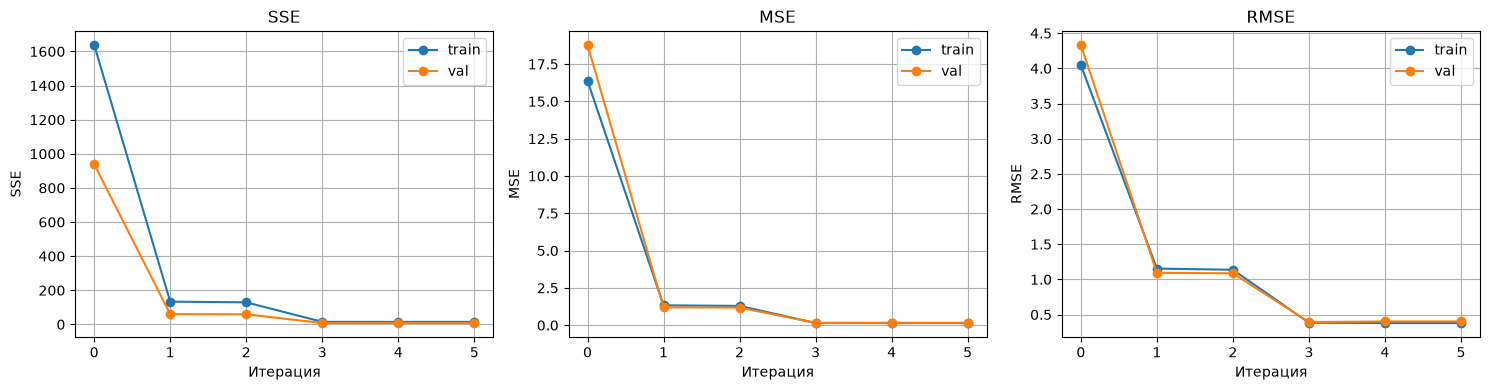

In [5]:
# Центрируем по train, чтобы учесть свободный член, как в Ridge.
x_mean = X_train.mean().to_numpy()
y_mean = y_train.mean()
X = X_train.to_numpy() - x_mean
y = y_train.to_numpy() - y_mean
Xv = X_val.to_numpy() - x_mean

A = X.T @ X
b = X.T @ y
w = np.zeros(X.shape[1])
r = b - A @ w
p = r.copy()

epsilon = 1e-8
max_iter = 100
history = []

for iteration in range(max_iter + 1):
    train_error = X @ w + y_mean - y_train.to_numpy()
    val_error = Xv @ w + y_mean - y_val.to_numpy()
    sse_train = np.sum(train_error ** 2)
    sse_val = np.sum(val_error ** 2)
    mse_train = sse_train / len(y_train)
    mse_val = sse_val / len(y_val)
    history.append([iteration, sse_train, sse_val, mse_train, mse_val,
                    np.sqrt(mse_train), np.sqrt(mse_val)])

    # Критерий из лекции: норма невязки меньше epsilon.
    if np.linalg.norm(r) < epsilon or iteration == max_iter:
        break

    step = (r @ r) / (p @ A @ p)
    w = w + step * p
    r_new = r - step * (A @ p)
    beta = (r_new @ r_new) / (r @ r)
    p = r_new + beta * p
    r = r_new

history = pd.DataFrame(history, columns=[
    "iteration", "SSE train", "SSE val", "MSE train", "MSE val",
    "RMSE train", "RMSE val"
])
display(history.round(6))
print("Число итераций:", iteration)
print("Норма невязки:", np.linalg.norm(r))
print("Ручное решение совпадает с Ridge:",
      np.allclose(Xv @ w + y_mean, model.predict(X_val), atol=1e-6, rtol=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["SSE", "MSE", "RMSE"]):
    ax.plot(history["iteration"], history[metric + " train"], "o-", label="train")
    ax.plot(history["iteration"], history[metric + " val"], "o-", label="val")
    ax.set_title(metric)
    ax.set_xlabel("Итерация")
    ax.set_ylabel(metric)
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

#### Ответьте на вопрос, какую модель Вы получили: обученную, переобученную или недообученную?

* если на графиках все три ошибки для обеих выборок падают - модель обучилась хорошо
* если на графиках ошибки на train падают, а на val с какого-то момента растут - модель переобучилась (подумайте, что стоит изменить в этом случае)
* если на графиках обе ошибки высокие - модель недообучилась (подумайте, что стоит изменить в этом случае)

Мы получили обученную модель, на всех графиках ошибки train и val падают

#### Шаг 6. Применяем модель на тестовой выборке, чтобы предсказать цены квартир.

1. Найдите y_predict

2. Для каждой квартиры из test выведите на экран:
* id квартиры
* её предсказанную цену
* её настоящую цену
* разницу между предсказанной и настоящей ценой (чтобы оценить насколько хорошо Ваша модель предсказывает цены)

3. сохранить получившуюся таблицу

P.S. В итоговой таблице все столбцы должны быть подписаны.

In [6]:
y_predict = model.predict(X_test)

result = pd.DataFrame({
    "id квартиры": data.iloc[150:]["apartment id"].to_numpy(),
    "Предсказанная цена": y_predict,
    "Настоящая цена": y_test.to_numpy(),
    "Разница (прогноз - факт)": y_predict - y_test.to_numpy()
})
display(result.round(3))
result.to_csv("test_predictions.csv", index=False, encoding="utf-8-sig")

sse_test = np.sum((y_predict - y_test.to_numpy()) ** 2)
mse_test = sse_test / len(y_test)
print(f"SSE test: {sse_test:.4f}")
print(f"MSE test: {mse_test:.4f}")
print(f"RMSE test: {np.sqrt(mse_test):.4f}")
print("Таблица сохранена в test_predictions.csv")

,id квартиры,Предсказанная цена,Настоящая цена,Разница (прогноз - факт)
0,151,20.887,21.54,-0.653
1,152,9.969,9.73,0.239
2,153,7.671,7.74,-0.069
3,154,10.470,10.15,0.320
4,155,17.601,17.27,0.331
5,156,8.995,8.23,0.765
6,157,8.356,8.52,-0.164
7,158,14.702,14.95,-0.248
8,159,8.453,8.16,0.293
9,160,14.879,14.95,-0.071


SSE test: 9.9893
MSE test: 0.1998
RMSE test: 0.4470
Таблица сохранена в test_predictions.csv


### Поздравляю! Вы обучили модель и уже сделали первый шаг в машинном обучении! Молодцы!